**International Stroke v3 (IST-3) Dataset**

*Source: https://datashare.ed.ac.uk/items/95f369ad-17a3-4032-b5ee-2f10b6fd724d*

About Dataset:
- NTS: INSERT DATASET INFORMATION HERE

Contents of Jupyter Notebook:
1) Exploratory Data Analysis:
- inspect dataset features and missing data points
- visualize demographic composition

2) Machine Learning:
- 

In [7]:
#initialise libraries and packages
import os
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import urllib.request

1) Exploratory Data Analysis

In [8]:
#initialise variables
variable_type = {
    'metadata_var': ['randhosp_id', 'randpat_id', 'pretrialexp', 'country', 'trialphase', 'phase',
                     'gender', 'weight', 'glucose', 'agecat', 'ageimp', 'age_true', 'UKextra'],
    'randomisation_var': ['age', 'randyear', 'randmonth', 'randhour', 'randmin', 'randdelay', 'livealone_rand', 
                          'indepinadl_rand', 'nobleed_rand', 'infarct', 'antiplat_rand', 'atrialfib_rand', 'sbprand', 
                          'dbprand', 'gcs_eye_rand', 'gcs_motor_rand', 'gcs_verbal_rand', 'gcs_score_rand', 'nihss', 
                          'liftarms_rand', 'ablewalk_rand', 'weakface_rand', 'weakarm_rand', 'weakleg_rand', 
                          'dysphasia_rand', 'hemianopia_rand', 'visuospat_rand', 'brainstemsigns_rand', 'otherdeficit_rand', 
                          'stroketype', 'pred_nihss', 'randvioltype', 'sbpstart', 'sbp30min', 'sbp60min', 'sbp24h', 
                          'dbpstart', 'dbp30min', 'dbp60min', 'dbp24h', 'treatdelay'],
    'treatment_var': ['itt_treat', 'recinfus', 'gotbolus', 'infus_start', 'infus_halt', 'totdose',
                      'nostartcode', 'treatment', 'haltcode'],
    'seven_day_var': ['other_antiplat_pre', 'anticoag_pre', 'asl', 'rec7', 'consent_type', 'aspirin_pre',
                      'dipyridamole_pre', 'clopidogrel_pre', 'lowdose_heparin_pre',
                      'fulldose_heparin_pre', 'warfarin_pre', 'antithromb_pre', 'hypertension_pre',
                      'diabetes_pre', 'stroke_pre', 'aspirin_day1', 'antiplatelet_day1',
                      'lowdose_heparin_day1', 'full_anticoag_day1', 'lowerBP_day1',
                      'nontrial_thromb_day1', 'iv_fluids_day1', 'insulin_day1', 'aspirin_days2to7',
                      'antiplatelet_days2to7', 'lowdose_heparin_days2to7', 'full_anticoag_days2to7',
                      'lowerBP_days2to7', 'nontrial_thromb_days2to7', 'nasogastric_days2to7',
                      'antibiotics_days2to7', 'findiag7', 'brainsite7', 'haem_type7', 'nonstroke_type7',
                      'med_adno', 'critcareno', 'strk_unitno', 'genwardno', 'adjudicated', 'sevendaycase',
                      'final_status', 'sich7', 'dead7', 'myocard_infarct', 'extracranial_bleed',
                      'allergic_reaction', 'other_effect', 'adverse_reaction', 'gcs_eye_7',
                      'gcs_motor_7', 'gcs_verbal_7', 'liftarms_7', 'ablewalk_7', 'indepinadl_7',
                      'destination', 'other_effect_code', 'event_days'],
    'six_months_var': ['konprob', 'recsix', 'sixmonthform', 'sixcompleted_by', 'ohs6', 'ordinal6',
                       'aliveind6', 'alivefav6', 'dead6mo', 'imputed6', 'aspirin6', 'bloodthin6',
                       'clotbust6', 'stocking6', 'gotprobs6', 'needhelp6', 'walkhelp6', 'speakprob6',
                       'mobility6', 'selfcare6', 'activities6', 'pain6', 'anxiety6', 'wherelive6',
                       'howlive6', 'euroqol6', 'deadordep6', 'missing6', 'surv6', 'censor6',
                       'disab_unknown6', 'vital_and_disabunknown6'],
    'eighteen_months_var': ['receighteen', 'eighteenmonthform', 'eighteencompleted_by', 'aspirin18',
                            'bloodthin18', 'clotbust18', 'stocking18', 'gotprobs18', 'needhelp18',
                            'walkhelp18', 'speakprob18', 'mobility18', 'selfcare18', 'activities18',
                            'pain18', 'anxiety18', 'wherelive18', 'howlive18', 'euroqol18',
                            'deadordep18', 'ohs18', 'ordinal18', 'aliveind18', 'alivefav18',
                            'yrfu_code', 'missing18', 'censor18', 'surv18', 'plan18', 'disab_unknown18',
                            'vital_and_disabunknown18'],
    'r_scan_var': ['recR', 'R_scantype', 'R_scannorm', 'waiver_code', 'extracranial_bleed_site',
                   'R_acuteic', 'hypodeg', 'hypodegsite', 'mca', 'affmca', 'aspcau', 'asplen',
                   'aspins', 'aspint', 'aspm1', 'aspm2', 'aspm3', 'aspm4', 'aspm5', 'aspm6', 'oial',
                   'aca', 'pca', 'subinf', 'cbzinf', 'cinf', 'stem', 'tisswell', 'hdart1', 'hdart2',
                   'hdart3', 'hdart4', 'hdart5', 'hdart6', 'hdart7', 'seclesion', 'redbtvola',
                   'redbtvolb', 'wmla', 'wmlp', 'oldlesion', 'oldlesion1', 'oldlesion2', 'oldlesion3',
                   'oldlesion4', 'oldlesion5', 'oldlesion6', 'nslesion', 'nslesion1', 'nslesion2',
                   'nslesion3', 'nslesion4', 'nslesion5', 'scanqual', 'R_infarct_size', 'apca',
                   'subinf1', 'cbzinf1', 'cinf1', 'stem1', 'aca1', 'pca1', 'R_infarct_territory',
                   'R_hypodensity', 'R_swelling', 'R_hyperdense_arteries', 'R_atrophy', 'R_whitematter',
                   'R_oldlesion', 'R_nonstroke_lesion', 'R_isch_change', 'R_mca_aspects',
                   'R_tot_aspects', 'R_hyperdensity', 'vis_infarct'],
    'p_scan_var': ['recP', 'P_scantype', 'P_scannorm'],
    'death_var': ['deathcode', 'deathdate_unknown'],
}


In [ ]:
# load dataset from local copy

df = pd.read_sas(r"C:\Users\nurai\OneDrive\Documents\GitHub\StrokePrediction\data\datashare_aug2015.sas7bdat",
                 encoding='utf-8')
df

,randhosp_id,randpat_id,pretrialexp,country,trialphase,phase,itt_treat,age,gender,deathcode,...,censor18,surv18,plan18,UKextra,disab_unknown6,vital_and_disabunknown6,disab_unknown18,vital_and_disabunknown18,treatment,haltcode
0,090,00001,2.0,UK,Open,2.0,0.0,81.0,1.0,E4,...,0.0,158.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
1,012,00002,1.0,SWEDEN,Open,2.0,1.0,92.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
2,043,00003,1.0,POLAND,Open,2.0,1.0,75.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,Placebo,NaN
3,077,00004,2.0,UK,Open,2.0,0.0,60.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,I63
4,043,00005,1.0,POLAND,Open,2.0,0.0,88.0,1.0,NaN,...,NaN,NaN,2.0,2.0,0.0,0.0,NaN,NaN,rt-PA,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3030,077,03031,2.0,UK,Open,2.0,1.0,83.0,1.0,E8,...,1.0,548.0,1.0,2.0,1.0,0.0,1.0,0.0,Placebo,NaN
3031,104,03032,1.0,BELGIUM,Open,2.0,0.0,83.0,1.0,E8,...,NaN,NaN,2.0,2.0,0.0,0.0,NaN,NaN,rt-PA,NaN
3032,148,03033,1.0,UK,Open,2.0,0.0,84.0,1.0,NaN,...,1.0,548.0,1.0,2.0,0.0,0.0,0.0,0.0,rt-PA,NaN
3033,149,03034,2.0,UK,Open,2.0,0.0,68.0,1.0,E1,...,0.0,2.0,2.0,1.0,0.0,0.0,NaN,NaN,rt-PA,NaN


In [10]:
# count number of patients enrolled
patient_count = df['randpat_id'].nunique()
patient_count

3035

In [11]:
# #import data source # nts: too long and times out
# try:
#     url = "https://datashare.ed.ac.uk/bitstreams/36194788-6f9d-4ff9-b462-b5701c07be48/download"
#     urllib.request.urlretrieve(url, "datashare_aug2015.sas7bdat")
#     df = pd.read_sas("datashare_aug2015.sas7bdat", encoding='utf-8', format="sas7bdat")
# except:
#     df = pd.read_sas(r"G:\My Drive\Portfolio\ISTD_v3_20260111\datashare_aug2015.sas7bdat",
#                  encoding='utf-8')

In [12]:
#summarise entries of variables
unique_df = pd.DataFrame({
    col: df[col].drop_duplicates().sort_values(ignore_index=True) for col in df.columns
})
# unique_df.to_csv(r"G:\My Drive\Portfolio\ISTD_v3_20260111\datashare_aug2015_unique.csv", index=False)
unique_df

,randhosp_id,randpat_id,pretrialexp,country,trialphase,phase,itt_treat,age,gender,deathcode,...,censor18,surv18,plan18,UKextra,disab_unknown6,vital_and_disabunknown6,disab_unknown18,vital_and_disabunknown18,treatment,haltcode
0,001,00001,1.0,AUSTRALIA,Blinded,1.0,0.0,31.935,1.0,E1,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,Placebo,I1
1,002,00002,2.0,BELGIUM,Open,2.0,1.0,40.000,NaN,E2,...,1.0,1.0,NaN,2.0,NaN,NaN,1.0,1.0,rt-PA,I2
2,003,00003,NaN,ITALY,NaN,NaN,NaN,41.000,NaN,E3,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I3
3,004,00004,NaN,NORWAY,NaN,NaN,NaN,42.000,NaN,E4,...,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I4
4,005,00005,NaN,OTHER,NaN,NaN,NaN,43.000,NaN,E7,...,NaN,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,I51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3030,NaN,03031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3031,NaN,03032,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3032,NaN,03033,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3033,NaN,03034,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# count number of hospitals
hospital_count = df['randhosp_id'].nunique()
hospital_count

156

In [15]:
# count number of hospitals with pre trial experience 
hospital_pretrialexp_df = df[['randhosp_id', 'pretrialexp']].drop_duplicates()
hospital_pretrialexp_count = len(hospital_pretrialexp_df[hospital_pretrialexp_df['pretrialexp']==2])
hospital_pretrialexp_count

80

In [16]:
# count number of countries
country_count = df['country'].nunique()
country_count

9

In [17]:
# count patients with unknown status
deathdateunknown_count = len(df[df['deathdate_unknown']==1])
deathdateunknown_count

11

In [18]:
# count alive patients within 18 months
alive_count = len(df[df['deathdate_unknown'].isna()])
alive_count

1731

In [19]:
# count dead patients within 18 months
dead_count = len(df[df['deathdate_unknown']==2])
dead_count

1293

Text(0.5, 1.0, 'Treatment of Enrolled Patients')

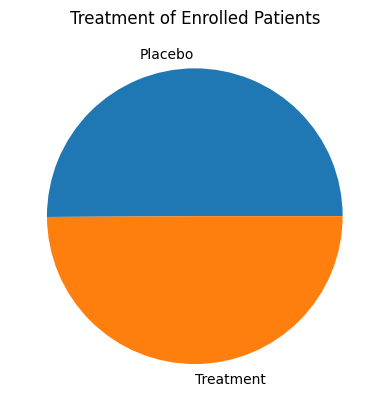

In [25]:
# plot treatment/placebo composition
plt.pie(df['itt_treat'].value_counts(), labels=['Placebo', 'Treatment'])
plt.title('Treatment of Enrolled Patients')

Text(0.5, 1.0, 'Gender Composition of Enrolled Patients')

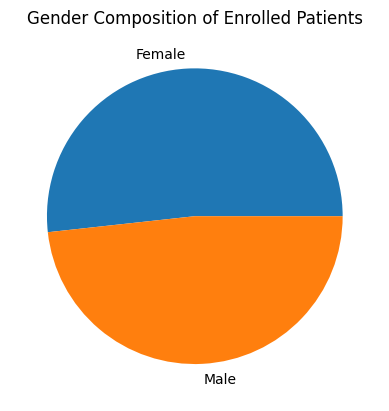

In [27]:
# plot gender composition
plt.pie(df['gender'].value_counts(), labels=['Female', 'Male'])
plt.title('Gender Composition of Enrolled Patients')

Text(0.5, 1.0, 'Age Distribution of Enrolled Patients')

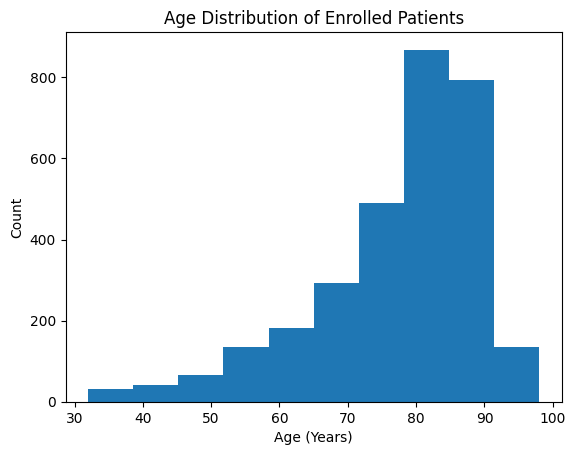

In [41]:
# plot age distribution
plt.hist(df['age'].round())
plt.xlabel('Age (Years)')
plt.ylabel('Count')
plt.title('Age Distribution of Enrolled Patients')

Text(0.5, 1.0, 'Weight Distibution of Enrolled Patients')

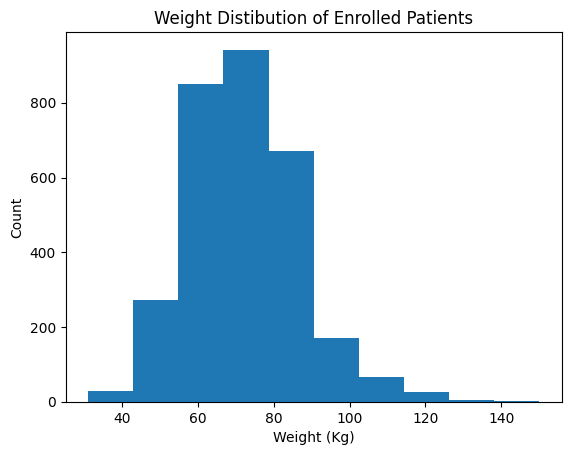

In [ ]:
# plot weight distribution
plt.hist(df['weight'])
plt.xlabel('Weight (Kg)')
plt.ylabel('Count')
plt.title('Weight Distribution of Enrolled Patients')

In [46]:
df['surv6'].value_counts(dropna=False)

surv6
183.0    2211
2.0        53
1.0        52
3.0        39
4.0        38
         ... 
50.0        1
111.0       1
97.0        1
143.0       1
108.0       1
Name: count, Length: 154, dtype: int64

In [43]:
df['surv18'].value_counts(dropna=False)

surv18
548.0    1553
NaN       238
183.0     188
2.0        49
1.0        48
         ... 
493.0       1
248.0       1
286.0       1
211.0       1
119.0       1
Name: count, Length: 350, dtype: int64

Text(0.5, 1.0, 'Survival Distribution of Enrolled Patients')

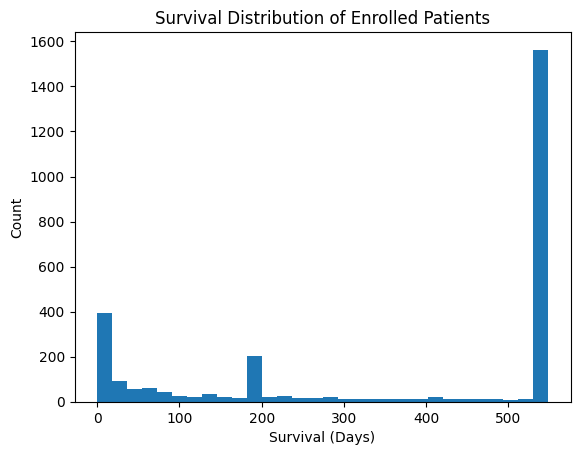

In [82]:
# plot survival distribution
plt.hist(df['surv18'], bins=30)
plt.xlabel('Survival (Days)')
plt.ylabel('Count')
plt.title('Survival Distribution of Enrolled Patients')

([<matplotlib.axis.XTick at 0x2986204ddc0>,
 [Text(0.0, 0, 'Treatment'), Text(1.0, 0, 'Placebo')])

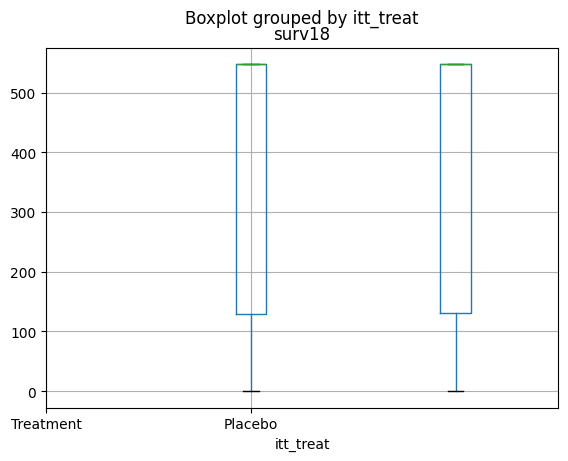

In [55]:
# plot survival distribution
df.boxplot(column='surv18', by='itt_treat') 
plt.xticks(ticks=[0.0, 1.0], labels=['Treatment', 'Placebo'])

2) Machine Learning

Data Cleaning and Validation
- ensure only patients with known status and death dates are included
- ensure patients with missing data removed

In [ ]:
# #drop entries with unknown date of death
# df[df['deathdate_unknown']==1]
# drop entries with no planned follow up after 6M, although some are
# df[(df['plan18'] == 2) & (df['surv18'].notna())] 
# drop entries with no planned follow up after 6M and unknown death date
df = df[(df['plan18']!=2) & (df['deathdate_unknown']!=1)]
df


In [ ]:
#create classification label 
conditions = [
    df['surv18'] < 8,
    df['surv18'] < 184,
    df['surv18'] >= 143
]

df['surv18_class'] = np.select(conditions, ["7 days", "6 months", "18 months"], default="Unknown")


In [ ]:
#format data
df['age'] = df['age'].round()

In [ ]:
#plot distribution of data (TBC)
plt.hist(df['surv18'])


In [ ]:
target = 'surv18' # for regression
# target = 'surv18_class' # for classification

#define predictor columns
clean_df = df[[target]+variable_type['metadata_var']+variable_type['randomisation_var']+['itt_treat']]
#drop columns 
clean_df.drop(columns=['randhosp_id', 'randpat_id', 'trialphase', 'agecat', 'ageimp', 'age_true', 'UKextra',
                     #   'gotbolus', 'infus_start', 'infus_halt', 'totdose', 'nostartcode', 'treatment', 'haltcode',
                       'randvioltype'], inplace=True)
clean_df

In [ ]:
clean_df.isna().sum()

In [ ]:
clean_df.dropna(how="any", inplace=True)

In [ ]:
clean_df.dtypes

In [ ]:
from sklearn.preprocessing import OneHotEncoder

#OHE string columns
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(clean_df[['country']])
encoded_df = pd.DataFrame(encoded,columns=encoder.get_feature_names_out(['country']),index=clean_df.index)

In [ ]:
clean_df = clean_df.join(encoded_df).drop(['country'], axis=1)

In [ ]:
clean_df

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(clean_df.drop(target, axis=1), clean_df[target], 
                                                    test_size=0.2, random_state=42)

In [ ]:
X_train

In [ ]:
import json

feature_names = X_train.columns.tolist()
with open("feature_names.json", "w") as f:
    json.dump(feature_names, f)

In [ ]:
y_train.iloc[0]

In [ ]:
# actual: 183
# linear regression prediction: 396.0586995197378
with open("dummy_data.json", "w") as f:
    json.dump(X_train.iloc[0].to_dict(), f)

In [ ]:
from pipeline.supervised_ml import RunRegressionModels

test_run = RunRegressionModels(X_train, y_train, X_test, y_test)
test_run.run_linear_regression(save_model=True)
test_run.run_lasso_regression()
test_run.run_lassocv_regression()
test_run.run_ridge_regression()
test_run.run_ridgecv_regression()
test_run.run_decisiontree_regression()
test_run.run_svm_regression()
test_run.run_randomforest_regression()
test_run.run_gradboost_regression()

In [ ]:
test_run.train_df

In [ ]:
test_run.train_df

In [ ]:
colors = plt.cm.hsv(np.linspace(0, 1, len(test_run.test_metrics_all.keys())))

fig = plt.figure(figsize=(10, 15))
gs = fig.add_gridspec(5, 1)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[3, 0])
ax5 = fig.add_subplot(gs[4, 0])  # Spans both columns

for ax, metric in zip([ax1, ax2, ax3, ax4, ax5], ['r2', 'evs', 'mae', 'mse', 'rmse']):
    for key, color in zip(test_run.test_metrics_all.keys(), colors):
        ax.bar(key, test_run.test_metrics_all[key][metric], color=color)
        ax.bar(key, test_run.train_metrics_all[key][metric], hatch="//", color=color, alpha=0.7)
        ax.set_title(f"Evaluation Metric: {metric}")

# plt.tight_layout()
# plt.show()

Note to self: 
* regression models in general are not able to capture relationship between variables and target well with low r2 and relatively high mae, considering max value of target is in the 500s
* models operating under the assumption of linearity perform similarly to each other, comparing train and test metrics dont seem to indicate overfitting, except for decision tree
* small improvement seen on random forest that doesnt assume linearity; non-linear models to explore further

To check:
* why is svm particularly bad?
* how to reduce overfitting on decision tree?
* uneven distribution of target, 
* does classification of target improve results?


In [ ]:
# save model
import joblib

joblib.dump(test_run.models['linear_reg'], "stroke_prediction_model.joblib")